APPROACH: Load entire dataset into the quantum circuit

In [1]:
%pip install numpy matplotlib pylatexenc "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import random
import numpy as np
import pandas as pd
import sys
from IPython.display import display
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution, plot_state_qsphere

In [3]:
N = 10
max_data_element = 10000

In [4]:
dataset = [random.randint(0,max_data_element) for _ in range(N)]
print("Dataset: ", dataset)

Dataset:  [7930, 9315, 1943, 4317, 6112, 2594, 8346, 9724, 7896, 5462]


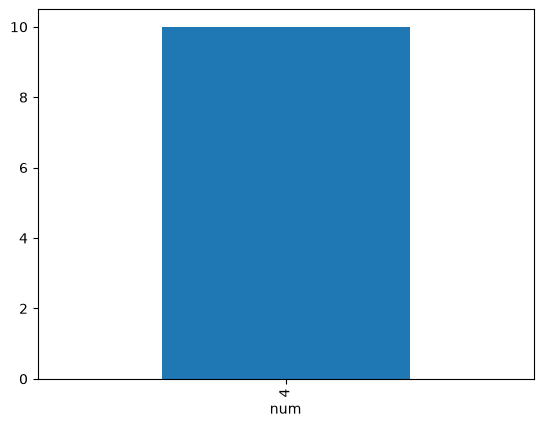

In [5]:
df = pd.DataFrame(
    dataset, columns=["num"]
)
df["num"].astype(str).str.len().value_counts().sort_index().plot(kind="bar")
plt.show()

In [6]:
def initialize(): # O(N)
  # quantum state = 1/root_N (summation_(N) |i>|0>|->)

  print("\nTotal qubits: ", total_qubits)
  qc = QuantumCircuit(total_qubits)

  print("Index qubits: ", index_q)

  # handling dataset of arbitrary size
  amplitudes = np.zeros(2**n, dtype=complex) # O(N)

  for i in range(2**n):  # O(N)
      amplitudes[i] = 1 / np.sqrt(2**n)

  state = Statevector(amplitudes)

  qc.initialize(state, range(n))
  qc.x(ancilla) # |0> --> |1>
  qc.h(ancilla) # |1> --> |->
  qc.barrier()

  return qc

In [7]:
def database_lookup(qc):  # O(N.(logN+d))
  # database values --encode--> quantum gates
  # U_d |i>|0>|-> = |i>|d>|->

  # FUTURE WORK: Improve this part, replace with qRAM ?
  # or maybe separate from grover search iterations as a preprocessing/state preparation step
  for index, value in enumerate(dataset): # O(N.(logN+d))
      zero_controls = []

      for bit in range(n):
          if ((index >> bit) & 1) == 0: # detects which index bits are 0
              qc.x(index_q[bit]) # 0 --> 1
              zero_controls.append(index_q[bit]) # to later convert 1 --> 0

      for bit in range(d):
          if ((value >> bit) & 1) == 1:
              qc.mcx(index_q, data_q[bit])  # data_q[bit] = 1

      for q in zero_controls:
          qc.x(q) # convert the previously converted 1 --> 0 (original)

  return qc

In [8]:
def mark_target(qc):  # O(d)
  # 1/root_N summation_(N) ( |i>|d>|-> ) --mark_target -->
  # 1/root_N ( -summation_(M) |i>|T>|-> + summation_(N-M) ( |i>|d>|-> ) )

  zero_controls = []

  for bit in range(d):
    if ((target >> bit) & 1) == 0:
        qc.x(data_q[bit])
        zero_controls.append(data_q[bit])

  qc.mcx(data_q, ancilla) # |-> --> -|-> (phase kickback for target)

  for q in zero_controls:
    qc.x(q)

  return qc

In [9]:
def oracle(): # O(N.(logN+d))
    qc = QuantumCircuit(total_qubits)

    database_lookup(qc) # O(N.(logN+d))
    qc.barrier()

    mark_target(qc) # O(d)
    qc.barrier()

    database_lookup(qc) # O(N.(logN+d))
    qc.barrier()

    return qc

In [10]:
def diffuser(): # O(1)
    # D = 2∣s⟩⟨s∣ − I
    # D∣ψ⟩ = ∑_i​ (2.mean − a_i​)∣i⟩

    qc = QuantumCircuit(n)

    qc.h(index_q) # makes the amplitude of |00...0> twice the mean of all the amplitudes
    qc.x(index_q) # |00...0> --> |11...1>

    if n == 1:  # only one qubit
        qc.z(0) # change the phase of the one qubit

    else:
        # H.MCX.H = MCZ (controlled phase flip)
        qc.h(n - 1) # qubit[n-1] is last index qubit
        qc.mcx(list(range(n - 1)), n - 1) # |11...1> --> - |11...1>
        qc.h(n - 1)

    qc.x(index_q) # |11...1> --> |00...0> has -2.mean amplitude
    qc.h(index_q) # inversion about mean: every amplitude = 2.mean - amplitude

    qc.barrier()

    return qc

In [11]:
def visualize(qc, text):
    no_of_locators_on_chart = 10    # shows maximum of 10 locators on the x-axis of the chart (decreases overcrowding)

    state = Statevector.from_instruction(qc)
    # display(plot_state_qsphere(state))
    probs_dict = state.probabilities_dict(qargs=index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()}  # convert binary index to decimal
    
    print(f"{text}: ", probs_dict)
    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))
    display(plot)

In [12]:
def grover_search(dataset, target, no_of_shots=10):
    theta = math.asin(math.sqrt(M / N)) + sys.float_info.epsilon
    no_of_iter = max(1, round(((math.pi / 4) * math.sqrt(N / M)) - 0.5))

    print(f"\nTheta: {theta}")
    print(f"Total no of iterations: {no_of_iter}")

    index_qubits = QuantumRegister(n, name="index")
    data_qubits = QuantumRegister(d, name="data")
    ancilla_qubit = QuantumRegister(1, name="ancilla")
    classical_register = ClassicalRegister(n, name="index_result")
    qc = QuantumCircuit(index_qubits, data_qubits, ancilla_qubit, classical_register)

    init = initialize() # O(N)
    qc.compose(init,inplace=True)
    visualize(qc, "Initial state")

    for iteration in range(no_of_iter):     # O(root_N * (N.(logN+d))) ≈ O(N^(3/2).logN)

        print(f"\nGROVER ITERATION {iteration+1}")

        print("\nORACLE")
        oracle_circuit = oracle()   # O(N.(logN+d))
        qc.compose(oracle_circuit, qubits=index_q + data_q + [ancilla],inplace=True)
        state_oracle = Statevector.from_instruction(qc)
        probs_dict = state_oracle.probabilities_dict(qargs=index_q)
        probs_dict = {int(k, 2): v for k, v in probs_dict.items()}
        visualize(qc, "Oracle output")

        print("\nDIFFUSER")
        diffuser_circuit = diffuser()   # O(1)
        qc.compose(diffuser_circuit, qubits=index_q, inplace=True)
        visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    measured_qc = qc.copy()
    measured_qc.measure(index_q, range(n))

    simulator = AerSimulator()
    compiled = transpile(measured_qc, simulator)
    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

    return measured_qc, result

In [13]:
N = len(dataset)
n = math.ceil(math.log2(N))

# PROBLEM: finding max O(N) and as d increases so does the number of qubits and the complexity of the circuit.
# it can be 32 bit or 64 integer depending on the system and hence would require as many qubits
d = math.ceil(math.log2(max(dataset) + 1))      

index_q = list(range(n))
data_q = list(range(n, n + d))
ancilla = n + d
total_qubits = n + d + 1

print("N = ", N)
print("n = ", n)
print("Index qubits = ", index_q)
print("Data qubits = ", data_q)
print("Ancilla = ", ancilla)
print("Total no of qubits = ", total_qubits)

N =  10
n =  4
Index qubits =  [0, 1, 2, 3]
Data qubits =  [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Ancilla =  18
Total no of qubits =  19


In [14]:
target = random.choice(dataset)
target

6112

In [15]:
# actual answer through classical search
target_indices = [
    i for i, value in enumerate(dataset)
    if value == target
]
M = len(target_indices)
target_indices

[4]


Theta: 0.3217505543966424
Total no of iterations: 2

Total qubits:  19
Index qubits:  [0, 1, 2, 3]
Initial state:  {0: np.float64(0.062499999999999986), 1: np.float64(0.062499999999999986), 2: np.float64(0.062499999999999986), 3: np.float64(0.062499999999999986), 4: np.float64(0.062499999999999986), 5: np.float64(0.062499999999999986), 6: np.float64(0.062499999999999986), 7: np.float64(0.062499999999999986), 8: np.float64(0.062499999999999986), 9: np.float64(0.062499999999999986), 10: np.float64(0.062499999999999986), 11: np.float64(0.062499999999999986), 12: np.float64(0.062499999999999986), 13: np.float64(0.062499999999999986), 14: np.float64(0.062499999999999986), 15: np.float64(0.062499999999999986)}


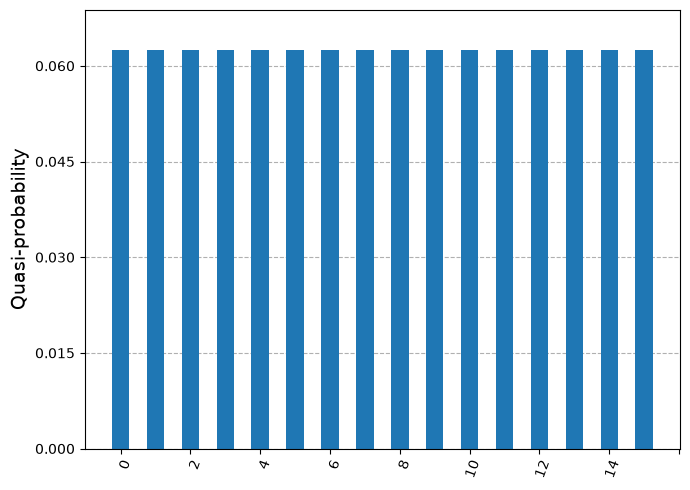


GROVER ITERATION 1

ORACLE
Oracle output:  {0: np.float64(0.06249999999993269), 1: np.float64(0.062499999999932734), 2: np.float64(0.06249999999993417), 3: np.float64(0.06249999999993401), 4: np.float64(0.06249999999993289), 5: np.float64(0.06249999999993314), 6: np.float64(0.062499999999935385), 7: np.float64(0.0624999999999348), 8: np.float64(0.062499999999934705), 9: np.float64(0.06249999999993401), 10: np.float64(0.06249999999993471), 11: np.float64(0.06249999999993523), 12: np.float64(0.06249999999993383), 13: np.float64(0.062499999999935656), 14: np.float64(0.06249999999993444), 15: np.float64(0.06249999999993454)}


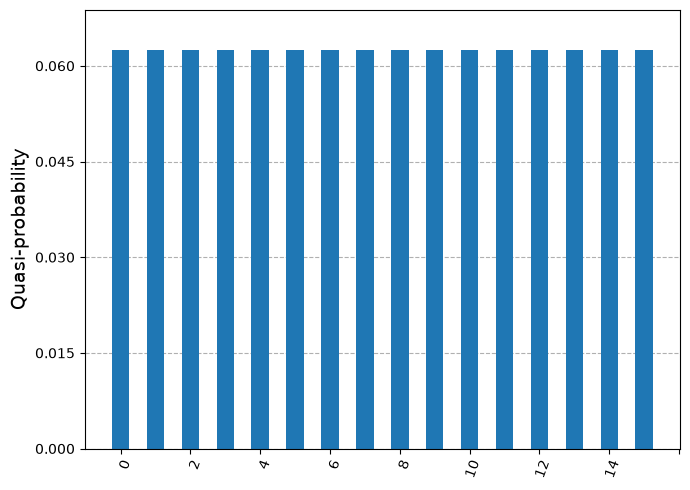


DIFFUSER
Diffuser output:  {0: np.float64(0.03515624999996425), 1: np.float64(0.03515624999996421), 2: np.float64(0.03515624999996317), 3: np.float64(0.0351562499999633), 4: np.float64(0.4726562499994986), 5: np.float64(0.03515624999996393), 6: np.float64(0.03515624999996225), 7: np.float64(0.03515624999996268), 8: np.float64(0.03515624999996274), 9: np.float64(0.03515624999996325), 10: np.float64(0.035156249999962766), 11: np.float64(0.03515624999996235), 12: np.float64(0.035156249999963404), 13: np.float64(0.03515624999996203), 14: np.float64(0.03515624999996296), 15: np.float64(0.03515624999996287)}


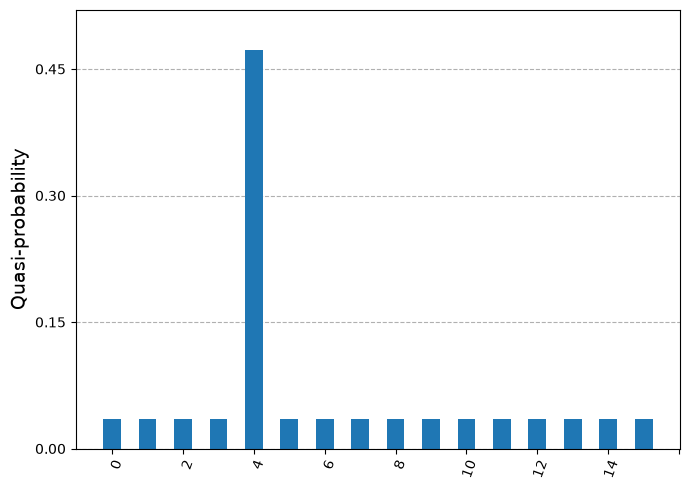


GROVER ITERATION 2

ORACLE
Oracle output:  {0: np.float64(0.03515624999992557), 1: np.float64(0.03515624999992618), 2: np.float64(0.03515624999992478), 3: np.float64(0.03515624999992585), 4: np.float64(0.472656249998988), 5: np.float64(0.03515624999992633), 6: np.float64(0.03515624999992614), 7: np.float64(0.0351562499999256), 8: np.float64(0.03515624999992547), 9: np.float64(0.03515624999992625), 10: np.float64(0.035156249999926156), 11: np.float64(0.03515624999992525), 12: np.float64(0.035156249999927024), 13: np.float64(0.03515624999992557), 14: np.float64(0.03515624999992656), 15: np.float64(0.03515624999992653)}


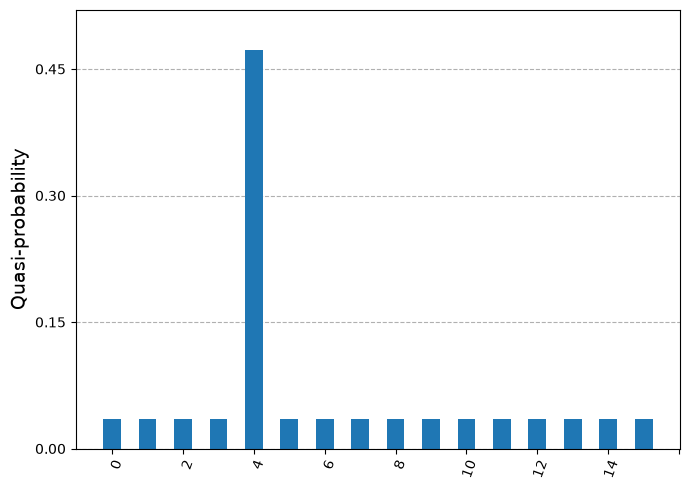


DIFFUSER
Diffuser output:  {0: np.float64(0.006103515624987515), 1: np.float64(0.006103515624987279), 2: np.float64(0.006103515624987862), 3: np.float64(0.006103515624987407), 4: np.float64(0.9084472656230644), 5: np.float64(0.006103515624987204), 6: np.float64(0.00610351562498729), 7: np.float64(0.0061035156249875065), 8: np.float64(0.006103515624987562), 9: np.float64(0.006103515624987246), 10: np.float64(0.006103515624987272), 11: np.float64(0.0061035156249876505), 12: np.float64(0.0061035156249869185), 13: np.float64(0.00610351562498752), 14: np.float64(0.00610351562498712), 15: np.float64(0.006103515624987121)}


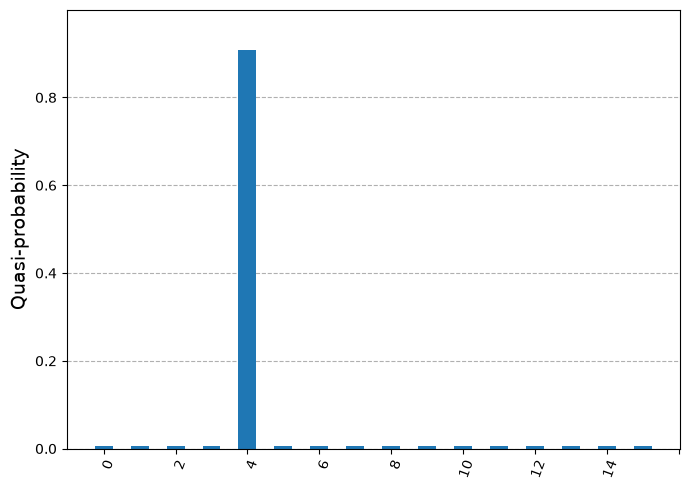


FINAL MEASUREMENT

Index measurement results for (10) shots:
{'1001': 1, '0100': 9}


In [16]:
qc, result = grover_search(dataset, target)

In [17]:
with open("grover_results.txt", "w") as f:
    f.write(str(result))



In [18]:
qc.draw("mpl")

In [19]:
print("Target = ", target)
print("Target index using classical search = ", target_indices)

counts = result.get_counts()
grover_bitstring = max(counts, key=counts.get)  # extract the bitstring with the highest count
grover_index = int(grover_bitstring[-n:], 2) # extract index bits and convert to decimal

print("\nTarget index using Grover search = ", grover_index)
print("Target value using Grover search = ", dataset[grover_index])

Target =  6112
Target index using classical search =  [4]

Target index using Grover search =  4
Target value using Grover search =  6112


In [20]:
index_probs = [
    (int(bitstring[-n:], 2), count)
    for bitstring, count in result.get_counts().items()
]
sorted_counts = sorted(index_probs, key=lambda x: x[1], reverse=True)
sorted_counts

[(4, 9), (9, 1)]

In [21]:
# ANSLYSIS

print("\nREGISTER ANALYSIS")

print("Dataset size   (N):", N)
print("Index qubits   (n):", len(index_q))
print("Data qubits    (d):", len(data_q))
print("Ancilla           :", 1)
print("Classical bits (n):", len(index_q))

print("\nCIRCUIT ANALYSIS")

print("Total qubits                                    :", qc.num_qubits)
print("Circuit width (quantum bits + classical bits)   :", qc.width())
print("Circuit size (total number of operations/gates) :", qc.size())
print("Circuit depth/layers                            :", qc.depth())

print("\nOPERATION COUNT")
print(qc.count_ops())


REGISTER ANALYSIS
Dataset size   (N): 10
Index qubits   (n): 4
Data qubits    (d): 14
Ancilla           : 1
Classical bits (n): 4

CIRCUIT ANALYSIS
Total qubits                                    : 19
Circuit width (quantum bits + classical bits)   : 23
Circuit size (total number of operations/gates) : 559
Circuit depth/layers                            : 383

OPERATION COUNT
OrderedDict({'mcx': 288, 'x': 245, 'h': 21, 'barrier': 9, 'measure': 4, 'initialize': 1})
